# A tour of Ashvini

This notebook runs the model on one small halo and shows, step by step, how to change it: a parameter, the feedback timing, the wind model that sets how much gas each supernova removes, a whole piece of physics, and finally the event integrator that follows individual supernovae. Everything runs in about a minute on a laptop. The reading guide is `docs/STUDENT_GUIDE.md`; the equations are in `MODELS.md`.

Each section ends with a short question. Try to answer it before you read the next cell.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from ashvini import config, utils
from ashvini.config import DEFAULT, override
from ashvini.main import run_forest, run_events

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
plt.rcParams.update({"figure.figsize": (7, 3.6), "axes.grid": True, "grid.alpha": 0.3})

## 1. A halo and its default run

A merger tree gives the mass of a halo at each redshift on a shared grid. The test suite ships a small one (five haloes per mass bin, z = 25 to 5; its growth-rate column is not consistent with its masses, see the note below). We take the first halo of the 10^8 Msun bin, which is small enough that supernovae matter a lot.

301 steps from z = 25 to 5; halo mass 6.39e+05 -> 1.00e+08 Msun


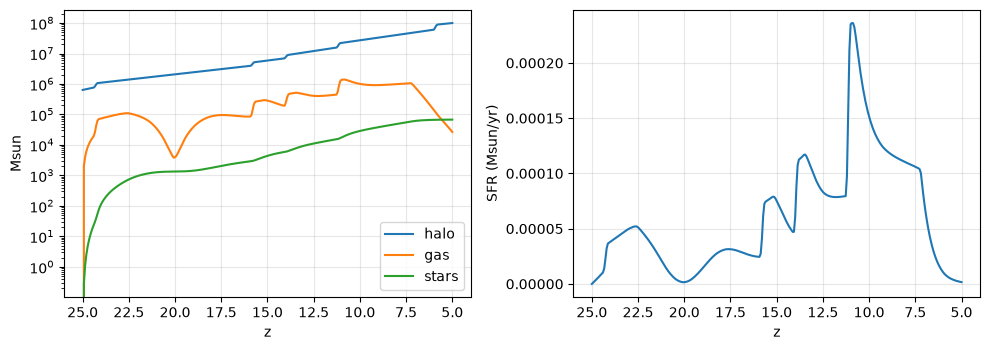

In [2]:
halo_mass, halo_growth, redshift = utils.read_trees(root / "tests/fixtures/merger_trees_fixture.h5", 1e8)
M = halo_mass[:1]                                   # one halo, shape (1, n_steps)
# The fixture was thinned in redshift without rescaling its growth-rate column, so that column does not integrate to the
# mass history. We take the rate from the mass history instead; then the grid and event integrators see the same supply.
Mdot = np.maximum(np.gradient(M, utils.time_at_z(redshift), axis=1), 0.0)
print(f"{M.shape[1]} steps from z = {redshift[0]:.0f} to {redshift[-1]:.0f}; halo mass {M[0,0]:.2e} -> {M[0,-1]:.2e} Msun")

default = run_forest(M, Mdot, redshift)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].semilogy(redshift, default["halo_mass"][0], label="halo"); ax[0].semilogy(redshift, default["gas_mass"][0], label="gas")
ax[0].semilogy(redshift, default["stars_mass"][0], label="stars"); ax[0].legend(); ax[0].set(xlabel="z", ylabel="Msun"); ax[0].invert_xaxis()
ax[1].plot(redshift, default["sfr"][0] * 1e-9); ax[1].set(xlabel="z", ylabel="SFR (Msun/yr)"); ax[1].invert_xaxis()
plt.tight_layout()

**Question.** The star formation rate is bursty. Which line of `MODELS.md` says why the gas mass oscillates?

## 2. Change a parameter

`config.DEFAULT` holds every parameter (the same values as `run_params.yaml`). `override` returns a changed copy and leaves the default alone, so two runs with different parameters can sit side by side.

In [3]:
fast = override(DEFAULT, **{"sf.efficiency": 0.03})
r = run_forest(M, Mdot, redshift, config=fast)
print("stars at z = 5, efficiency 0.015 -> 0.03:", f"{default['stars_mass'][0,-1]:.3e} -> {r['stars_mass'][0,-1]:.3e}",
      f"(x{r['stars_mass'][0,-1]/default['stars_mass'][0,-1]:.2f})")

stars at z = 5, efficiency 0.015 -> 0.03: 6.784e+04 -> 6.858e+04 (x1.01)


**Question.** Doubling the efficiency changes the stars at z = 5 by about one per cent. Why? (Look at what the supernovae do to the gas.)

## 3. Feedback timing

`sn.type` is `"delayed"` (stars explode `delay_time` after they form), `"instantaneous"`, or `"no"`.

{'delayed': '6.78e+04', 'instantaneous': '6.74e+04', 'no': '5.06e+05'}


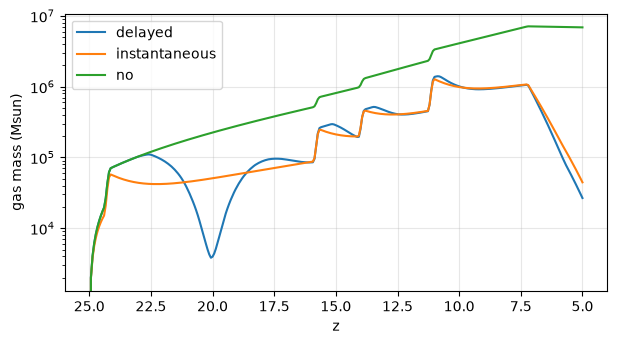

In [4]:
runs = {t: run_forest(M, Mdot, redshift, config=override(DEFAULT, **{"sn.type": t})) for t in ("delayed", "instantaneous", "no")}
for t, r in runs.items():
    plt.semilogy(redshift, r["gas_mass"][0], label=t)
plt.gca().invert_xaxis(); plt.legend(); plt.xlabel("z"); plt.ylabel("gas mass (Msun)")
print({t: f"{r['stars_mass'][0,-1]:.2e}" for t, r in runs.items()})

**Question.** With `"no"` feedback, where does the extra gas go?

## 4. How long after forming the stars explode

The default puts every explosion exactly 15 Myr after formation (`sn.delay_distribution = "single_delay"`). A real population has a range of lifetimes, from 3 Myr for a 100 Msun star to 37 Myr for an 8 Msun star. `sn.delay_distribution = "stellar_lifetimes"` spreads the explosions over that range. The IMF delay_distribution needs the supernova mass range to go up to 100 Msun, so we change that too.

Text(0, 0.5, 'gas mass (Msun)')

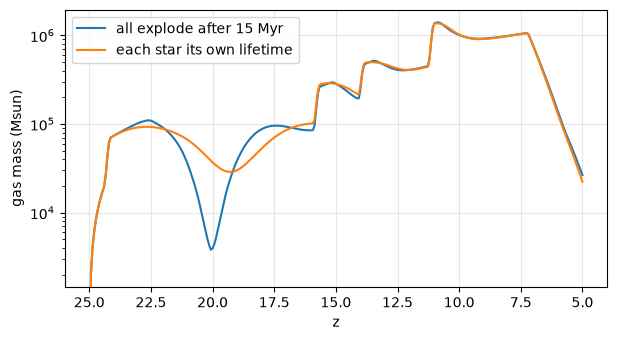

In [5]:
imf_delays = override(DEFAULT, **{"sn.delay_distribution": "stellar_lifetimes", "sn.m_sn_max": 100.0})
r_imf = run_forest(M, Mdot, redshift, config=imf_delays)
plt.semilogy(redshift, default["gas_mass"][0], label="all explode after 15 Myr")
plt.semilogy(redshift, r_imf["gas_mass"][0], label="each star its own lifetime")
plt.gca().invert_xaxis(); plt.legend(); plt.xlabel("z"); plt.ylabel("gas mass (Msun)")

**Question.** Why is the gas curve smoother when the explosions are spread over a range of delays?

## 5. How much gas a supernova removes: the wind model

`sn.wind_model` (the wind model) chooses between Ashvini's calibrated mass loading (`"ashvini"`, the default), a momentum-conserving wind (`"momentum"`: each supernova removes f_p p_SN / v_esc), and an energy-conserving wind (`"energy"`: each removes 2 eps_fb E_SN / v_esc^2). Here is the mass removed per unit mass of stars formed, for a halo at z = 10.

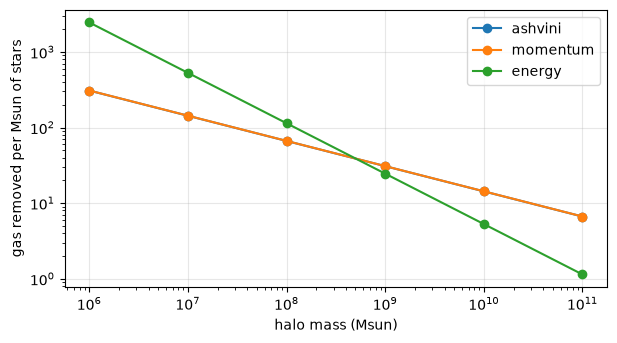

In [6]:
from ashvini.components.wind_model import make_wind_model
masses = np.logspace(6, 11, 6)
for name, extra in (("ashvini", {}), ("momentum", {"sn.f_p": 0.7646, "sn.m_sn_max": 100.0}), ("energy", {"sn.eps_fb": 0.1, "sn.m_sn_max": 100.0})):
    c = make_wind_model(override(DEFAULT, **{"sn.wind_model": name, **extra}))
    plt.loglog(masses, c.mass_loading(10.0, masses, 0.0), "o-", label=name)
plt.xlabel("halo mass (Msun)"); plt.ylabel("gas removed per Msun of stars"); plt.legend()

**Question.** The momentum curve lies on top of Ashvini's; the energy curve is steeper. What does that say about how Ashvini's wind is powered, and in which halo masses do the three wind models disagree most?

## 6. Replace a piece of physics

The model advances in time by calling components in turn. Each component is an object with a few methods, held as an attribute, so you can swap one. Here is a star formation law whose efficiency rises with redshift (a made-up law, for illustration), put in place of the default one.

Text(0, 0.5, 'stellar mass (Msun)')

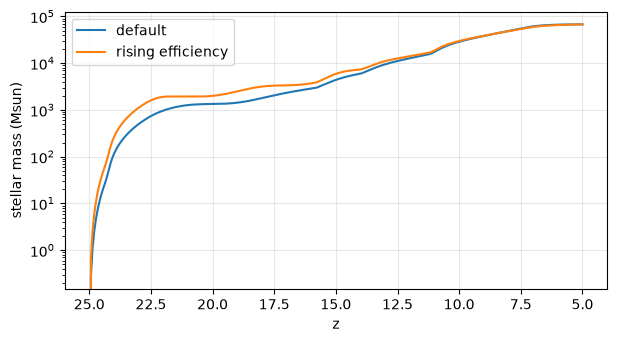

In [7]:
from ashvini.integrators.grid import GridIntegrator
from ashvini.components.star_formation import FreeFallStarFormation

class RisingEfficiency(FreeFallStarFormation):
    # efficiency per free-fall time grows as (1 + z) / 11, equal to the default at z = 10
    def rate_coefficient(self, redshift):
        return super().rate_coefficient(redshift) * (1.0 + redshift) / 11.0

integrator = GridIntegrator()
integrator.star_formation = RisingEfficiency(DEFAULT)
state, _ = integrator.run(M, Mdot, redshift)
plt.semilogy(redshift, default["stars_mass"][0], label="default")
plt.semilogy(redshift, state.stars_mass[0], label="rising efficiency")
plt.gca().invert_xaxis(); plt.legend(); plt.xlabel("z"); plt.ylabel("stellar mass (Msun)")

**Exercise.** Write a star formation law that stops below a gas density threshold. Which methods does the time integrator call on `star_formation`? (Search `integrators/grid.py` for `self.star_formation`.)

## 7. Following individual supernovae: the event integrator

The grid integrator treats supernova feedback as a smooth rate. The event integrator follows each supernova: stars form in short steps, the sampler says which massive stars they contain and when those explode, and each explosion removes gas at its own time, never more than the gas present. `sampler="smooth"` uses the expected supernovae (no randomness); `sampler="stochastic"` draws whole supernovae at random. The sampler needs `sn.m_sn_max = 100` and a lifetime metallicity (default 0.002).

14 s
stars at z = 5: smooth 1.36e+05; stochastic mean 1.36e+05, scatter 2%


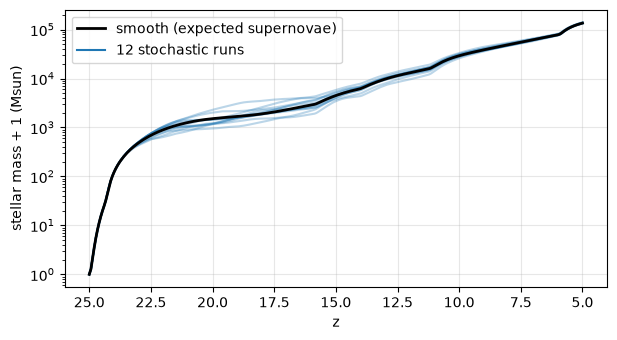

In [8]:
import time
ev = override(DEFAULT, **{"sn.m_sn_max": 100.0, "sn.wind_model": "momentum", "sn.f_p": 0.7646, "reion.UVB_enabled": False})
t0 = time.time()
smooth = run_events(M, Mdot, redshift, config=ev, sampler="smooth")
runs = [run_events(M, Mdot, redshift, config=ev, sampler="stochastic", seed=s) for s in range(12)]
print(f"{time.time()-t0:.0f} s")
for r in runs:
    plt.semilogy(redshift, r["stars_mass"][0] + 1, color="C0", alpha=0.3)
plt.semilogy(redshift, smooth["stars_mass"][0] + 1, "k", lw=2, label="smooth (expected supernovae)")
plt.plot([], [], color="C0", label="12 stochastic runs")
plt.gca().invert_xaxis(); plt.legend(); plt.xlabel("z"); plt.ylabel("stellar mass + 1 (Msun)")
final = np.array([r["stars_mass"][0, -1] for r in runs])
print(f"stars at z = 5: smooth {smooth['stars_mass'][0,-1]:.2e}; stochastic mean {final.mean():.2e}, scatter {final.std(ddof=1)/final.mean():.0%}")

**Question.** The stochastic runs scatter around the smooth one. In which halo mass range would you expect the scatter to matter most, and why?

## 8. Adding more physics to the event integrator

The `events` section of the config holds optional features, all off by default: a cooling threshold for star formation, a delay in the gas reaching the galaxy, gas falling back after it was blown out, explosion energy kept for removing gas that arrives later, a limit on the fraction of the gas one supernova can reach, a different energy coupling above a halo mass, and a wind travel time (`MODELS.md` has the table). Each is checked against Stochastic_Occupation. Here are three.

Text(0, 0.5, 'stellar mass + 1 (Msun)')

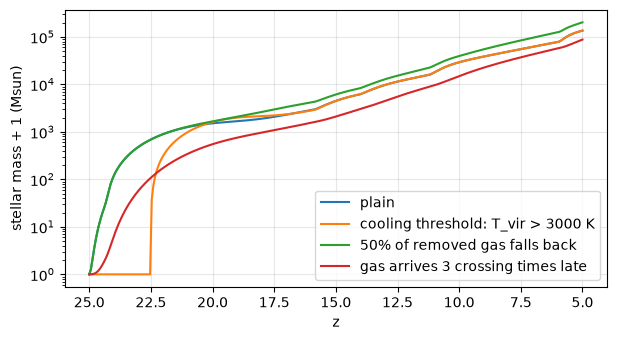

In [9]:
variants = {
    "plain": {},
    "cooling threshold: T_vir > 3000 K": {"events.cooling_T_vir_K": 3.0e3},
    "50% of removed gas falls back": {"events.recycling_fraction": 0.5},
    "gas arrives 3 crossing times late": {"events.inflow_delay_in_crossing_times": 3.0},
}
for label, change in variants.items():
    r = run_events(M, Mdot, redshift, config=override(ev, **change), sampler="smooth")
    plt.semilogy(redshift, r["stars_mass"][0] + 1, label=label)
plt.gca().invert_xaxis(); plt.legend(); plt.xlabel("z"); plt.ylabel("stellar mass + 1 (Msun)")

## Exercises

1. Make a plot of the stellar mass at z = 5 against `sf.efficiency` (five values from 0.005 to 0.08). Is it a power law? Where does it flatten, and what sets that?
2. The default delay is 15 Myr. Scan `sn.delay_time` from 0 to 100 Myr (use `sn.type = "delayed"`; at 0 the code treats the feedback as instantaneous). Which delay maximises the stellar mass of the 10^8 halo? Explain it in terms of when the gas peaks.
3. Compare the three wind models at equal f_p / eps_fb tuned so the stellar mass at z = 5 is the same. What differs between the runs?
4. Write your own component: for example a black hole that never grows (`components/blackholes.py` shows the interface), or a wind model whose mass loading is a power law of halo mass.
5. Using `run_events`, measure how the scatter of the final stellar mass depends on halo mass (use the 10^10 bin of the fixture, then 10^8). Where does the scatter vanish?
6. Turn on `events.reachable_gas_fraction = 0.05` with `sn.wind_model = "energy"` and `sn.eps_fb = 1`. Run the smooth sampler with `sampler_kwargs={"K": 50}` and `{"K": 200}`. Why do the answers differ? (See `docs/SUPERSET_DESIGN.md`, section 8.)